# Computer Vision & Convolutional Neural Networks  
## Interactive Jupyter Notebook

Welcome to the Computer Vision lesson.

In this notebook, you will learn how computers represent images, how images become NumPy arrays, how convolution filters detect patterns, and how Convolutional Neural Networks classify handwritten digits.

---

## What You Will Learn

By the end of this notebook, you should be able to:

1. Explain how digital images are represented as numerical matrices.
2. Describe image tensors using height, width, and color channels.
3. Visualize image data using NumPy and Matplotlib.
4. Normalize pixel values for neural networks.
5. Explain why flattening images can lose spatial information.
6. Manually implement a simple convolution operation using NumPy.
7. Explain the main layers of a CNN.
8. Build and train a basic CNN on MNIST.
9. Evaluate model performance.
10. Test model predictions and reflect on model limitations.

# Part 1: From Recommendation Systems to Computer Vision

In the previous project, the model used structured data.

Example:

```text
genre_match
movie_popularity
watch_time
previous_rating
recent_like
```

The model predicted:

```text
Recommend or Do Not Recommend
```

In Computer Vision, the input is different.

Instead of rows of user/movie features, we give the model an image.

The model predicts a label.

Example:

```text
Image of handwritten digit → 7
Image of cat → Cat
Image of dog → Dog
```

The key idea is:

```text
Images are numbers.
```

# Part 2: Images as Numerical Matrices

A digital image is made of pixels.

A pixel is the smallest unit of an image.

For a grayscale image:

- `0` usually means black
- `255` usually means white
- Values between 0 and 255 are shades of gray

For the computer, an image is like a spreadsheet of brightness values.

In [1]:
import numpy as np

# Create a small 8x8 grayscale image manually
small_image = np.array([
    [0,   0,   0,   0,   0,   0,   0,   0],
    [0,   0, 255, 255, 255, 255,  0,   0],
    [0,   0,   0,   0,   0, 255,  0,   0],
    [0,   0,   0, 255, 255, 255,  0,   0],
    [0,   0,   0,   0,   0, 255,  0,   0],
    [0,   0, 255, 255, 255, 255,  0,   0],
    [0,   0,   0,   0,   0,   0,  0,   0],
    [0,   0,   0,   0,   0,   0,  0,   0]
])

print(small_image)
print("Shape:", small_image.shape)

[[  0   0   0   0   0   0   0   0]
 [  0   0 255 255 255 255   0   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0   0 255 255 255   0   0]
 [  0   0   0   0   0 255   0   0]
 [  0   0 255 255 255 255   0   0]
 [  0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0]]
Shape: (8, 8)


## Visualizing the Image

The array above is just numbers, but Matplotlib can display it as an image.

We use:

```python
plt.imshow(image, cmap="gray")
```

The `cmap="gray"` setting tells Matplotlib to display it as a grayscale image.

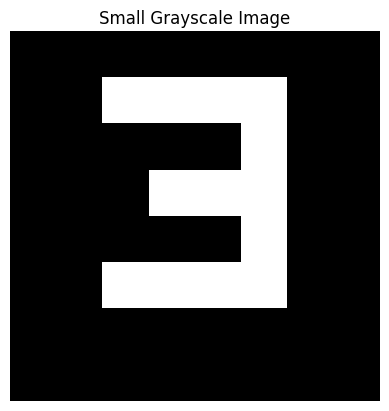

In [2]:
import matplotlib.pyplot as plt

plt.imshow(small_image, cmap="gray")
plt.title("Small Grayscale Image")
plt.axis("off")
plt.show()

## Practice 1: Create Your Own Image

Create your own 8×8 NumPy array.

Try to draw a simple pattern such as:

- a line
- a square
- the digit 1
- the digit 7
- a cross

Then display it using Matplotlib.

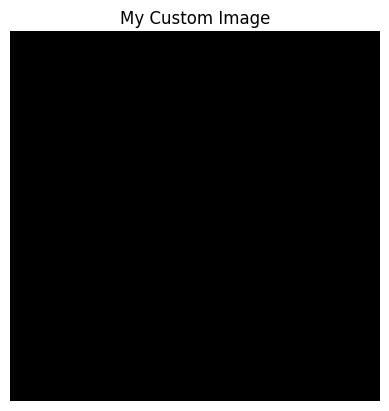

In [3]:
# Practice 1: Create your own 8x8 image

my_image = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0]
])

# Display your image
plt.imshow(my_image, cmap="gray")
plt.title("My Custom Image")
plt.axis("off")
plt.show()

# Part 3: Image Shape and Tensors

Images have shapes.

A grayscale image usually has this shape:

```text
height × width
```

A color image usually has this shape:

```text
height × width × color_channels
```

For color images, the channels are usually:

```text
Red, Green, Blue
```

This is called RGB.

A tensor is a multi-dimensional array.

Examples:

```text
28 × 28              → grayscale image
28 × 28 × 1          → grayscale image with channel dimension
28 × 28 × 3          → color image
60000 × 28 × 28 × 1  → batch of many grayscale images
```

In [4]:
# Grayscale image shape
gray_image = np.zeros((28, 28))

# RGB image shape
rgb_image = np.zeros((28, 28, 3))

print("Grayscale image shape:", gray_image.shape)
print("RGB image shape:", rgb_image.shape)

Grayscale image shape: (28, 28)
RGB image shape: (28, 28, 3)


## Practice 2: Tensor Shapes

Answer the following:

1. What does `(28, 28)` mean?
2. What does `(28, 28, 3)` mean?
3. What does `(100, 28, 28, 1)` mean?

Write your answers as comments below.

In [5]:
# Practice 2: Write your answers as comments

# 1.
# 2.
# 3.

# Part 4: Loading the MNIST Dataset

MNIST is a famous dataset of handwritten digits.

It contains images of digits from 0 to 9.

Each image is:

```text
28 pixels tall × 28 pixels wide
```

We will use MNIST to train a digit classifier.

In [6]:
# Import TensorFlow/Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import mnist

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)


## Viewing One MNIST Image

Let's look at one image and its label.

Image shape: (28, 28)
Label: 5
Raw pixel values:
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0  

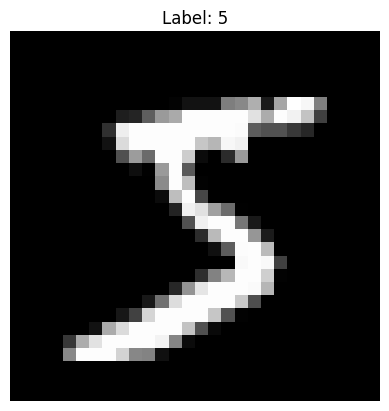

In [7]:
index = 0

img = X_train[index]
label = y_train[index]

print("Image shape:", img.shape)
print("Label:", label)
print("Raw pixel values:")
print(img)

plt.imshow(img, cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

## Practice 3: Explore More Images

Change the value of `index` to view different images.

Try:

```python
index = 1
index = 10
index = 100
index = 500
```

Observe:

- What digit is shown?
- What does the raw matrix look like?
- Are most values close to 0 or close to 255?

Image shape: (28, 28)
Label: 3


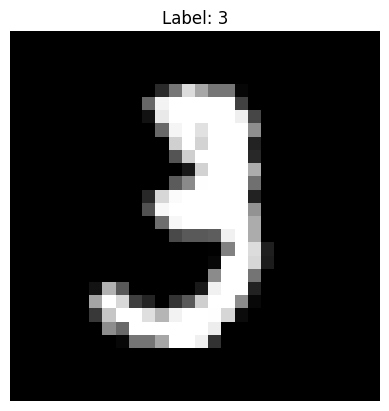

In [8]:
# Practice 3: Change this index and run the cell

index = 10

img = X_train[index]
label = y_train[index]

print("Image shape:", img.shape)
print("Label:", label)

plt.imshow(img, cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

# Part 5: Normalization

Pixel values are usually between 0 and 255.

Neural networks usually train better when numbers are smaller and scaled consistently.

So we normalize:

```text
old range: 0 to 255
new range: 0 to 1
```

We do this by dividing by 255.

```python
X_train = X_train / 255.0
```

Simple explanation:

```text
Normalization makes the image easier for the neural network to digest.
```

In [9]:
# Before normalization
print("Before normalization:")
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

# Normalize
X_train_normalized = X_train / 255.0
X_test_normalized = X_test / 255.0

print("\nAfter normalization:")
print("Minimum pixel value:", X_train_normalized.min())
print("Maximum pixel value:", X_train_normalized.max())

Before normalization:
Minimum pixel value: 0
Maximum pixel value: 255

After normalization:
Minimum pixel value: 0.0
Maximum pixel value: 1.0


## Practice 4: Normalization Check

Pick one image and print:

1. The original pixel values.
2. The normalized pixel values.
3. The minimum and maximum values before and after normalization.

In [10]:
# Practice 4

index = 0

original_img = X_train[index]
normalized_img = X_train_normalized[index]

print("Original image min:", original_img.min())
print("Original image max:", original_img.max())

print("Normalized image min:", normalized_img.min())
print("Normalized image max:", normalized_img.max())

Original image min: 0
Original image max: 255
Normalized image min: 0.0
Normalized image max: 1.0


# Part 6: Why Flattening Can Be a Problem

A 28×28 image has 784 pixels.

A regular neural network can flatten the image into one long list:

```text
28 × 28 → 784
```

However, flattening loses spatial context.

Spatial context means information about which pixels are near each other.

Why this matters:

If a digit shifts slightly left, the flattened list changes a lot.

CNNs solve this by looking at small neighborhoods of pixels.

In [11]:
# Flatten one MNIST image
img = X_train_normalized[0]

flattened_img = img.reshape(784)

print("Original shape:", img.shape)
print("Flattened shape:", flattened_img.shape)
print("First 20 flattened values:")
print(flattened_img[:20])

Original shape: (28, 28)
Flattened shape: (784,)
First 20 flattened values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## Visual Intuition

Flattening is like taking a picture and stretching all its pixels into one long row.

A CNN does something smarter:

```text
Look at small regions
Find local patterns
Combine patterns
Classify image
```

# Part 7: What Is Convolution?

A convolution uses a small filter, also called a kernel, to scan an image.

The filter slides over the image.

At each position:

1. Take a small image patch.
2. Multiply patch values by filter values.
3. Add the results.
4. Store the result in a new grid.

The new grid is called a feature map.

Feature maps show where patterns were detected.

In [12]:
# Small example image
simple_image = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 1, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0]
])

# Vertical edge filter
vertical_filter = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
])

print("Image:")
print(simple_image)

print("\nFilter:")
print(vertical_filter)

Image:
[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 0 0 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]

Filter:
[[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]


## Manual Convolution Function

Now we will write a simple convolution function using NumPy.

This is not as fast as TensorFlow, but it helps us understand how CNNs work.

In [13]:
def apply_filter(image, kernel):
    image_height, image_width = image.shape
    kernel_height, kernel_width = kernel.shape

    output_height = image_height - kernel_height + 1
    output_width = image_width - kernel_width + 1

    output = np.zeros((output_height, output_width))

    for row in range(output_height):
        for col in range(output_width):
            image_patch = image[row:row + kernel_height, col:col + kernel_width]
            output[row, col] = np.sum(image_patch * kernel)

    return output

feature_map = apply_filter(simple_image, vertical_filter)

print("Feature map:")
print(feature_map)

Feature map:
[[-1. -1.  1.]
 [-2. -1.  2.]
 [-1. -1.  1.]]


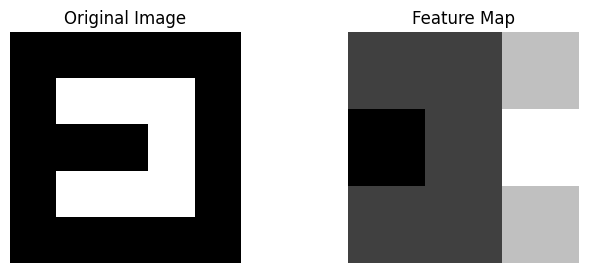

In [14]:
plt.figure(figsize=(8, 3))

plt.subplot(1, 2, 1)
plt.imshow(simple_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(feature_map, cmap="gray")
plt.title("Feature Map")
plt.axis("off")

plt.show()

## Practice 5: Try a Different Filter

Try the horizontal edge filter below.

What kind of pattern does it detect?

[[ 0. -1. -1.]
 [ 0.  0.  0.]
 [ 0.  1.  1.]]


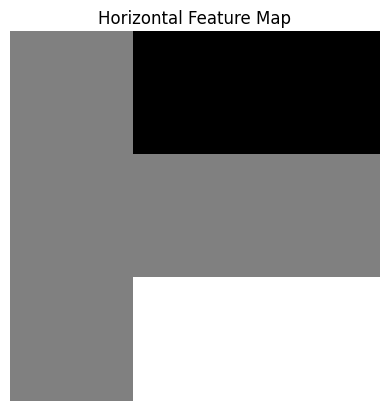

In [15]:
horizontal_filter = np.array([
    [ 1,  1,  1],
    [ 0,  0,  0],
    [-1, -1, -1]
])

# Practice 5: Apply the horizontal filter
horizontal_feature_map = apply_filter(simple_image, horizontal_filter)

print(horizontal_feature_map)

plt.imshow(horizontal_feature_map, cmap="gray")
plt.title("Horizontal Feature Map")
plt.axis("off")
plt.show()

# Part 8: CNN Architecture

A Convolutional Neural Network usually has these layers:

## 1. Convolutional Layer
Detects local patterns using filters.

## 2. Activation Layer
Usually ReLU. Adds non-linearity.

## 3. Pooling Layer
Shrinks feature maps while keeping important information.

## 4. Flatten Layer
Turns feature maps into a 1D vector.

## 5. Dense Layer
Makes the final classification decision.

For MNIST:

```text
Image → Conv2D → ReLU → Pooling → Flatten → Dense → Digit Prediction
```

# Part 9: Reshaping MNIST for CNNs

Keras CNN layers expect images to include a channel dimension.

MNIST starts as:

```text
(number_of_images, 28, 28)
```

We need:

```text
(number_of_images, 28, 28, 1)
```

The `1` means one grayscale channel.

In [16]:
X_train_cnn = X_train_normalized.reshape(-1, 28, 28, 1)
X_test_cnn = X_test_normalized.reshape(-1, 28, 28, 1)

print("CNN training shape:", X_train_cnn.shape)
print("CNN testing shape:", X_test_cnn.shape)

CNN training shape: (60000, 28, 28, 1)
CNN testing shape: (10000, 28, 28, 1)


# Part 10: Build a Small CNN

We will build a simple CNN for digit classification.

The final layer has 10 neurons because there are 10 classes:

```text
0, 1, 2, 3, 4, 5, 6, 7, 8, 9
```

The final activation is `softmax`.

Softmax turns the outputs into probabilities.

In [17]:
model = keras.Sequential([
    keras.layers.Conv2D(
        filters=16,
        kernel_size=(3, 3),
        activation="relu",
        input_shape=(28, 28, 1)
    ),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

model.summary()

/Users/adityavarma/PycharmProjects/Circuit Stream Adult/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2704)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        86,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 87,050 (340.04 KB)

 Trainable params: 87,050 (340.04 KB)

 Non-trainable params: 0 (0.00 B)

## Compile the CNN

Compiling tells Keras:

1. Which optimizer to use.
2. Which loss function to use.
3. Which metric to track.

For MNIST labels, we use:

```python
loss="sparse_categorical_crossentropy"
```

because the labels are integers from 0 to 9.

In [18]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Part 11: Train the CNN

Training may take a few minutes depending on your computer.

To keep class time manageable, we will train for a small number of epochs.

An epoch means the model has gone through the training data once.

In [19]:
history = model.fit(
    X_train_cnn,
    y_train,
    epochs=3,
    validation_split=0.1,
    batch_size=64
)

Epoch 1/3
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9122 - loss: 0.3031 - val_accuracy: 0.9692 - val_loss: 0.1186
Epoch 2/3
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9663 - loss: 0.1142 - val_accuracy: 0.9785 - val_loss: 0.0839
Epoch 3/3
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9760 - loss: 0.0824 - val_accuracy: 0.9827 - val_loss: 0.0674


# Part 12: Visualize Training Performance

We can plot accuracy and loss to see how the model improved during training.

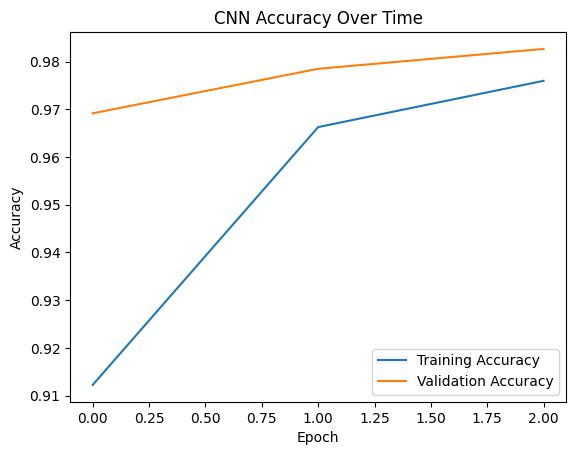

In [20]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy Over Time")
plt.legend()
plt.show()

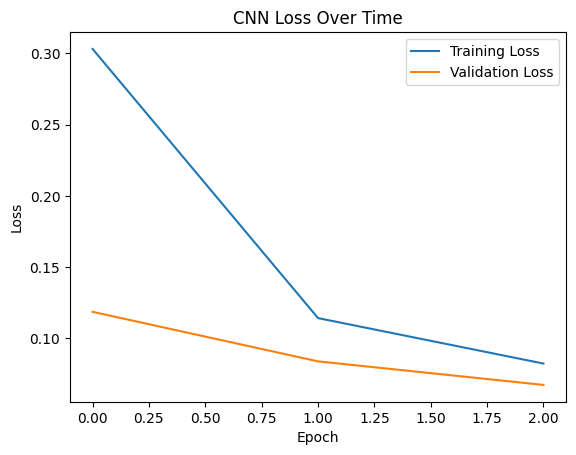

In [21]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss Over Time")
plt.legend()
plt.show()

# Part 13: Evaluate the Model

Evaluation tests the model on images it did not train on.

In [22]:
test_loss, test_accuracy = model.evaluate(X_test_cnn, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 703us/step - accuracy: 0.9780 - loss: 0.0669
Test Loss: 0.06689846515655518
Test Accuracy: 0.9779999852180481


# Part 14: Make Predictions

The model outputs probabilities for each digit.

We use `np.argmax()` to pick the digit with the highest probability.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
Raw prediction probabilities:
[[3.0780707e-06 3.2650800e-07 2.2172129e-05 2.1946169e-05 3.8570425e-07
  5.4003198e-07 6.8451994e-10 9.9991918e-01 1.3889227e-06 3.0982490e-05]]
Predicted label: 7
Actual label: 7


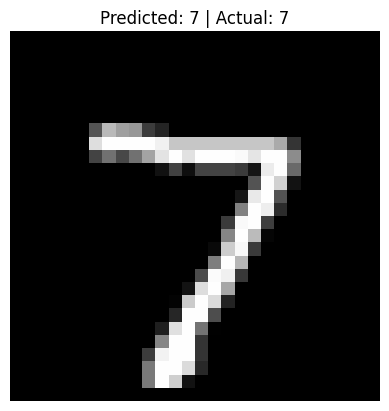

In [23]:
prediction = model.predict(X_test_cnn[0].reshape(1, 28, 28, 1))

print("Raw prediction probabilities:")
print(prediction)

predicted_label = np.argmax(prediction)

print("Predicted label:", predicted_label)
print("Actual label:", y_test[0])

plt.imshow(X_test[0], cmap="gray")
plt.title(f"Predicted: {predicted_label} | Actual: {y_test[0]}")
plt.axis("off")
plt.show()

## Practice 6: Test More Predictions

Change the value of `index`.

Try at least 5 different images.

For each one:

1. Display the image.
2. Print the predicted label.
3. Print the actual label.
4. Decide whether the model was correct.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
Predicted label: 0
Actual label: 0
Confidence: 0.9997687


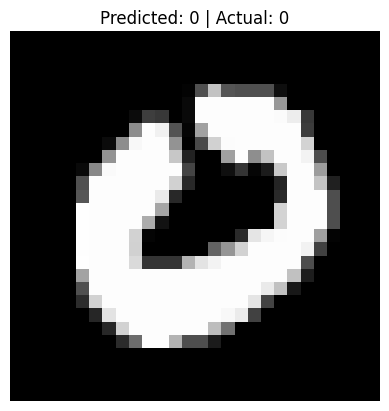

In [24]:
# Practice 6

index = 25

prediction = model.predict(X_test_cnn[index].reshape(1, 28, 28, 1))
predicted_label = np.argmax(prediction)

print("Predicted label:", predicted_label)
print("Actual label:", y_test[index])
print("Confidence:", np.max(prediction))

plt.imshow(X_test[index], cmap="gray")
plt.title(f"Predicted: {predicted_label} | Actual: {y_test[index]}")
plt.axis("off")
plt.show()

# Part 15: Inspect Prediction Confidence

The model gives a probability for each digit.

Let's display the confidence for each class.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Digit 0: 0.9998
Digit 1: 0.0000
Digit 2: 0.0000
Digit 3: 0.0000
Digit 4: 0.0000
Digit 5: 0.0000
Digit 6: 0.0002
Digit 7: 0.0000
Digit 8: 0.0000
Digit 9: 0.0000


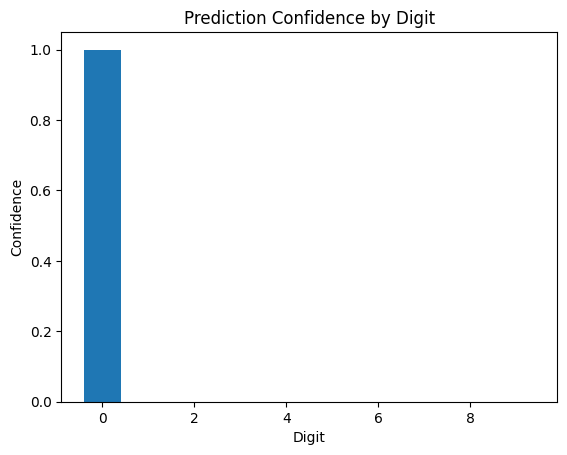

In [25]:
index = 25

prediction = model.predict(X_test_cnn[index].reshape(1, 28, 28, 1))[0]

for digit, confidence in enumerate(prediction):
    print(f"Digit {digit}: {confidence:.4f}")

plt.bar(range(10), prediction)
plt.xlabel("Digit")
plt.ylabel("Confidence")
plt.title("Prediction Confidence by Digit")
plt.show()

# Part 16: Binary Classification Version

Before classifying all digits from 0 to 9, it can help to think about a simpler binary problem.

Example:

```text
Is this digit a 3?
```

Output:

```text
1 = yes, it is a 3
0 = no, it is not a 3
```

This is binary classification.

In [26]:
# Create binary labels: 1 if digit is 3, otherwise 0
y_train_is_3 = (y_train == 3).astype(int)
y_test_is_3 = (y_test == 3).astype(int)

print("Original labels:", y_train[:20])
print("Binary labels for 'is 3':", y_train_is_3[:20])

Original labels: [5 0 4 1 9 2 1 3 1 4 3 5 3 6 1 7 2 8 6 9]
Binary labels for 'is 3': [0 0 0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 0 0]


## Build a Binary CNN

The final layer has 1 neuron with sigmoid activation because this is a yes/no problem.

In [27]:
binary_model = keras.Sequential([
    keras.layers.Conv2D(8, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

binary_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

binary_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1352)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │        21,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,745 (84.94 KB)

 Trainable params: 21,745 (84.94 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
binary_history = binary_model.fit(
    X_train_cnn,
    y_train_is_3,
    epochs=2,
    validation_split=0.1,
    batch_size=64
)

Epoch 1/2
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9623 - loss: 0.1269 - val_accuracy: 0.9838 - val_loss: 0.0785
Epoch 2/2
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9863 - loss: 0.0710 - val_accuracy: 0.9923 - val_loss: 0.0526


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
Actual digit: 7
Probability image is a 3: 0.003787177


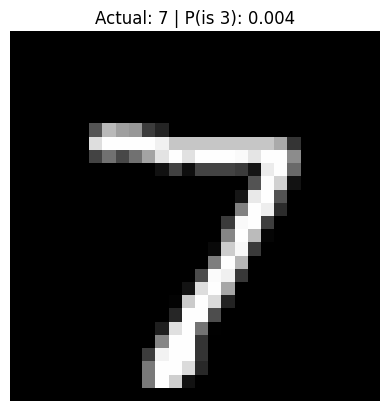

In [29]:
index = 0

probability_is_3 = binary_model.predict(X_test_cnn[index].reshape(1, 28, 28, 1))[0][0]

print("Actual digit:", y_test[index])
print("Probability image is a 3:", probability_is_3)

plt.imshow(X_test[index], cmap="gray")
plt.title(f"Actual: {y_test[index]} | P(is 3): {probability_is_3:.3f}")
plt.axis("off")
plt.show()

# Part 17: CNN Architecture Experiment

Now you will experiment with the number of filters.

Filters control how many visual patterns the CNN can learn.

Try changing:

```python
filters=8
filters=16
filters=32
```

Questions:

1. Does adding more filters improve accuracy?
2. Does training take longer?
3. Does the model improve faster?

In [30]:
# Practice 7: Change the number of filters

experiment_model = keras.Sequential([
    keras.layers.Conv2D(8, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

experiment_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

experiment_history = experiment_model.fit(
    X_train_cnn,
    y_train,
    epochs=2,
    validation_split=0.1,
    batch_size=64
)

Epoch 1/2
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9029 - loss: 0.3356 - val_accuracy: 0.9662 - val_loss: 0.1225
Epoch 2/2
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9625 - loss: 0.1268 - val_accuracy: 0.9720 - val_loss: 0.1006


# Part 18: Testing the Limits

Real models are not perfect.

They may struggle when:

- The digit is off-center.
- The lines are too thin.
- The lines are too thick.
- The digit is messy.
- The digit looks like another digit.

This is important because testing a model means trying examples that reveal its weaknesses.

## Independent Work: Testing the Limits

When you connect this model to a Streamlit app, test:

### Position Test
Draw a digit in the far corner instead of the center.

### Thickness Test
Draw the same digit with thin lines and thick lines.

### Messy Digit Test
Draw a digit that looks like two numbers.

### Reflection
Record:

1. What did the model predict?
2. How confident was it?
3. What kind of mistake did it make?
4. What does this tell you about the model?

# Part 19: Streamlit Extension Plan

After training the CNN, students can connect it to a Streamlit app.

The app should:

1. Let the user draw a digit.
2. Convert the drawing to a 28×28 grayscale image.
3. Normalize the image.
4. Pass it into the CNN.
5. Display the predicted digit and confidence.

Example app flow:

```text
Canvas Input
↓
Image Preprocessing
↓
CNN Prediction
↓
Display Digit + Confidence
```

In [31]:
# Optional: Save the trained model for a Streamlit app

model.save("mnist_cnn_model.keras")

print("Model saved as mnist_cnn_model.keras")

Model saved as mnist_cnn_model.keras
